# Physiological stress-response analysis

Exploratory analysis of heart rate (BPM) and peripheral temperature recorded by the ESP32 + web app during a rest → cognitive stress → recovery protocol.

**Data:** 6 sessions, one participant each (S01–S06), anonymized, in `../data/`. Four sessions used the Stroop task and one used PASAT; sessions recorded with older app versions have a different sampling interval (0.5 s vs 1.5 s) and column name (`stroop_correcto` vs `test_correcto`). This notebook harmonizes them.

**Questions**
1. Does heart rate rise during the stress phase and fall back during recovery?
2. Does peripheral temperature follow the phases, or just drift over the whole session?
3. Is there a time lag between the heart-rate response and any temperature response?

> With n = 6 and no control session, everything here is **exploratory**. No claims about stress physiology in general.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

DATA_DIR = Path("../data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

PHASES = ["reposo", "estres", "recuperacion"]
LABEL = {"reposo": "Rest", "estres": "Stress", "recuperacion": "Recovery"}
SHADE = {"reposo": "#e8f5e9", "estres": "#fff3e0", "recuperacion": "#e3f2fd"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load and harmonize

In [2]:
def load_session(path):
    subject, task, date = re.match(r"(S\d+)_(\w+?)_(\d{4}-\d{2}-\d{2})", path.name).groups()
    df = pd.read_csv(path, comment="#")                       # lines starting with '#' are metadata
    df = df.rename(columns={"stroop_correcto": "test_correcto"})  # older app versions
    df["subject"], df["task"], df["date"] = subject, task, date
    return df

raw = pd.concat([load_session(p) for p in sorted(DATA_DIR.glob("S[0-9][0-9]_*.csv"))], ignore_index=True)
print(f"{raw.subject.nunique()} sessions, {len(raw)} rows loaded")

# Rows with a task answer are separate events; the rest are periodic samples from the ESP32.
raw["is_answer"] = raw["test_correcto"].notna()

# Older app versions kept recording after recovery ended (phase 'fin'): drop those rows.
n_fin = int((raw.fase == "fin").sum())
raw = raw[raw.fase.isin(PHASES)].copy()
print(f"Dropped {n_fin} rows labeled 'fin'.")

samples = raw[~raw.is_answer].copy()
answers = raw[raw.is_answer].copy()
print(f"{len(samples)} sensor samples, {len(answers)} task answers")

6 sessions, 2626 rows loaded
Dropped 46 rows labeled 'fin'.
2177 sensor samples, 403 task answers


In [3]:
rows = []
for sid, g in samples.groupby("subject"):
    d = {"subject": sid, "task": g.task.iloc[0], "date": g.date.iloc[0],
         "sampling_s": round(g.elapsed_s.diff().median(), 1)}
    for ph in PHASES:
        e = g.loc[g.fase == ph, "elapsed_s"]
        d[f"{LABEL[ph].lower()}_s"] = round(e.max() - e.min())
    rows.append(d)
overview = pd.DataFrame(rows).set_index("subject")
overview

,task,date,sampling_s,rest_s,stress_s,recovery_s
subject,,,,,,
S01,Stroop,2026-04-20,0.5,59,59,59
S02,Stroop,2026-04-24,0.5,60,90,59
S03,Stroop,2026-05-21,0.5,60,60,60
S04,Stroop,2026-05-21,0.5,119,60,120
S05,PASAT,2026-05-25,1.5,119,178,118
S06,Stroop,2026-05-27,1.5,58,119,58


## 2. Per-session metrics

Samples are averaged into 1-second bins so that sessions with different sampling intervals are comparable. Short gaps (countdowns between phases) are interpolated.

In [4]:
def one_second_series(g):
    g = g.sort_values("elapsed_s")
    sec = np.floor(g.elapsed_s).astype(int)
    out = g.groupby(sec).agg(bpm=("bpm", "mean"), temp=("temperatura", "mean"), phase=("fase", "first"))
    out = out.reindex(pd.RangeIndex(out.index.min(), out.index.max() + 1))
    out["bpm_i"] = out.bpm.interpolate(limit=15)
    out["temp_i"] = out.temp.interpolate(limit=15)
    return out

series, rows = {}, []
for sid, g in samples.groupby("subject"):
    s = one_second_series(g)
    series[sid] = s
    m = g.groupby("fase")[["bpm", "temperatura"]].mean()
    rest_bpm, rest_t = m.loc["reposo", "bpm"], m.loc["reposo", "temperatura"]
    t0 = g.loc[g.fase == "estres", "elapsed_s"].min()

    # Peak heart-rate response: highest 10 s rolling mean in the first 60 s of stress, relative to rest
    smooth = s.bpm_i.rolling(10, center=True, min_periods=5).mean()
    peak = smooth.loc[int(t0): int(t0) + 60].max() - rest_bpm

    # Temperature trend (deg C per minute) within each phase
    slope = {ph: np.polyfit(gp.elapsed_s, gp.temperatura, 1)[0] * 60
             for ph, gp in ((ph, g[g.fase == ph]) for ph in PHASES)}

    ans = answers.loc[answers.subject == sid, "test_correcto"].astype(float)
    rows.append({
        "subject": sid, "task": g.task.iloc[0],
        "bpm_rest": rest_bpm, "bpm_stress": m.loc["estres", "bpm"], "bpm_recovery": m.loc["recuperacion", "bpm"],
        "d_bpm_stress": m.loc["estres", "bpm"] - rest_bpm,
        "d_bpm_recovery": m.loc["recuperacion", "bpm"] - rest_bpm,
        "peak_d_bpm": peak,
        "temp_rest": rest_t, "d_temp_stress": m.loc["estres", "temperatura"] - rest_t,
        "d_temp_recovery": m.loc["recuperacion", "temperatura"] - rest_t,
        "slope_rest": slope["reposo"], "slope_stress": slope["estres"], "slope_recovery": slope["recuperacion"],
        "pearson_all": g.bpm.corr(g.temperatura),
        "accuracy": ans.mean() if len(ans) else np.nan, "n_answers": len(ans),
    })
summary = pd.DataFrame(rows).set_index("subject")
summary.round(2).to_csv("session_summary.csv")
summary.round(2)

,task,bpm_rest,bpm_stress,bpm_recovery,d_bpm_stress,d_bpm_recovery,peak_d_bpm,temp_rest,d_temp_stress,d_temp_recovery,slope_rest,slope_stress,slope_recovery,pearson_all,accuracy,n_answers
subject,,,,,,,,,,,,,,,,
S01,Stroop,62.50,81.61,62.79,19.12,0.29,30.30,31.69,-0.21,-0.47,-0.24,-0.16,-0.32,0.09,0.60,5
S02,Stroop,77.28,91.24,71.92,13.96,-5.36,22.92,28.17,-0.19,-0.43,-0.14,-0.17,-0.18,0.27,0.89,46
S03,Stroop,63.98,66.76,73.48,2.78,9.50,10.07,28.96,-0.98,-2.15,-1.15,-0.97,-1.01,-0.50,1.00,43
S04,Stroop,86.08,94.41,92.70,8.33,6.61,11.97,31.71,-0.78,-1.10,-0.39,-0.44,-0.09,-0.61,0.80,30
S05,PASAT,67.80,65.07,68.25,-2.73,0.45,-3.15,33.73,0.71,0.68,0.59,0.04,0.07,-0.31,0.40,159
S06,Stroop,78.18,79.97,71.80,1.80,-6.38,12.58,29.05,-0.06,-0.11,0.05,-0.08,0.00,0.70,0.72,120


Columns: `d_bpm_*` = phase mean minus rest mean; `peak_d_bpm` = peak 10-s heart-rate rise in the first minute of stress; `slope_*` = temperature trend in °C/min within each phase; `pearson_all` = whole-session BPM–temperature correlation (the number the app reports). `accuracy` is only meaningful with enough answers (`n_answers`).

## 3. Sessions at a glance

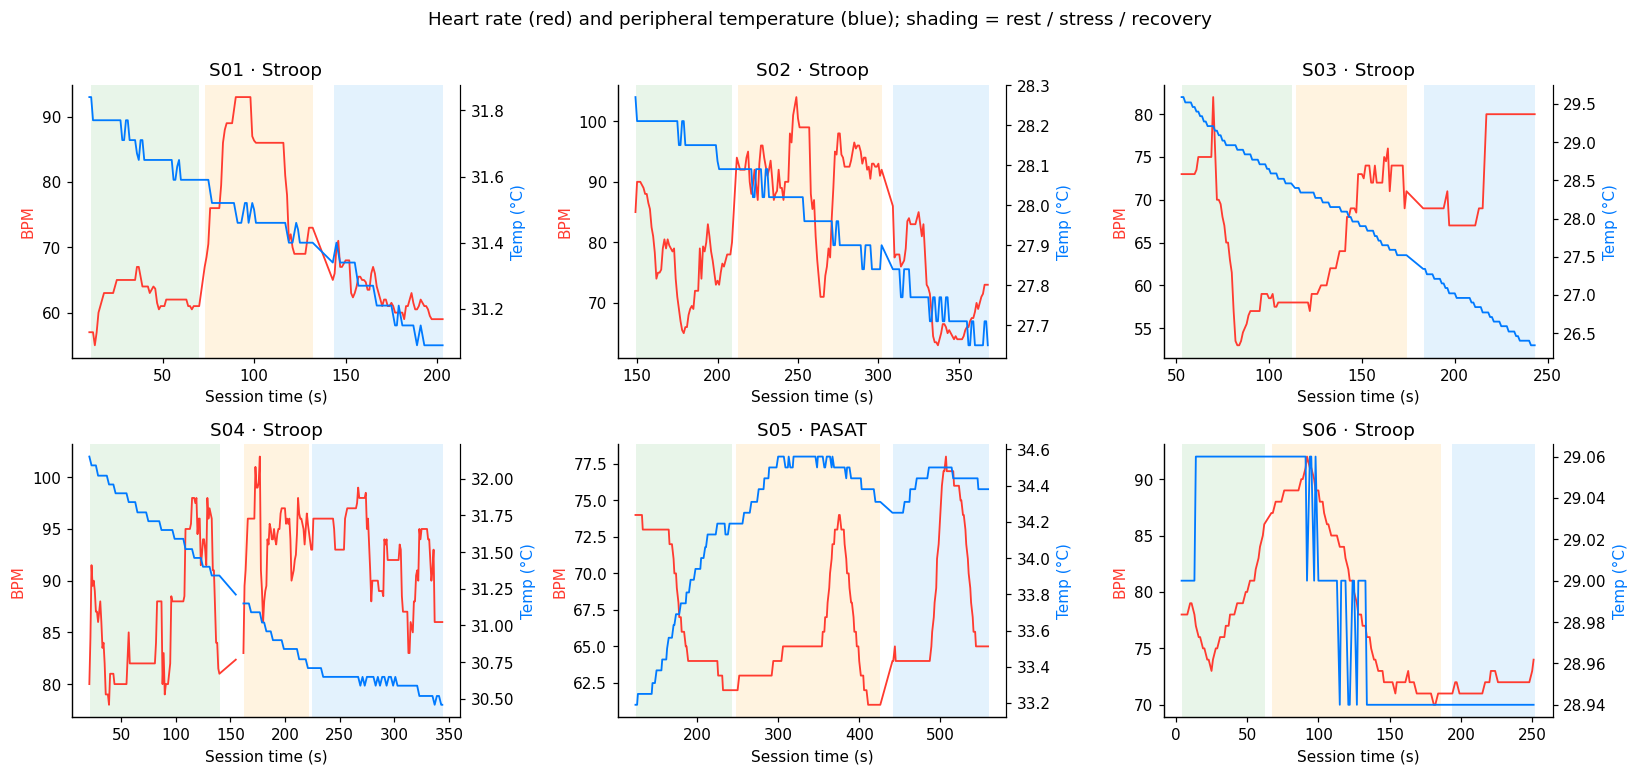

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (sid, s) in zip(axes.ravel(), series.items()):
    g = samples[samples.subject == sid]
    for ph in PHASES:
        e = g.loc[g.fase == ph, "elapsed_s"]
        ax.axvspan(e.min(), e.max(), color=SHADE[ph], lw=0)
    ax.plot(s.index, s.bpm_i, color="#ff3b30", lw=1.2)
    ax.set_ylabel("BPM", color="#ff3b30")
    ax2 = ax.twinx()
    ax2.plot(s.index, s.temp_i, color="#007aff", lw=1.2)
    ax2.set_ylabel("Temp (°C)", color="#007aff")
    ax2.spines["right"].set_visible(True)
    ax.set_title(f"{sid} · {summary.loc[sid, 'task']}")
    ax.set_xlabel("Session time (s)")
fig.suptitle("Heart rate (red) and peripheral temperature (blue); shading = rest / stress / recovery", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_sessions.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Heart rate across phases

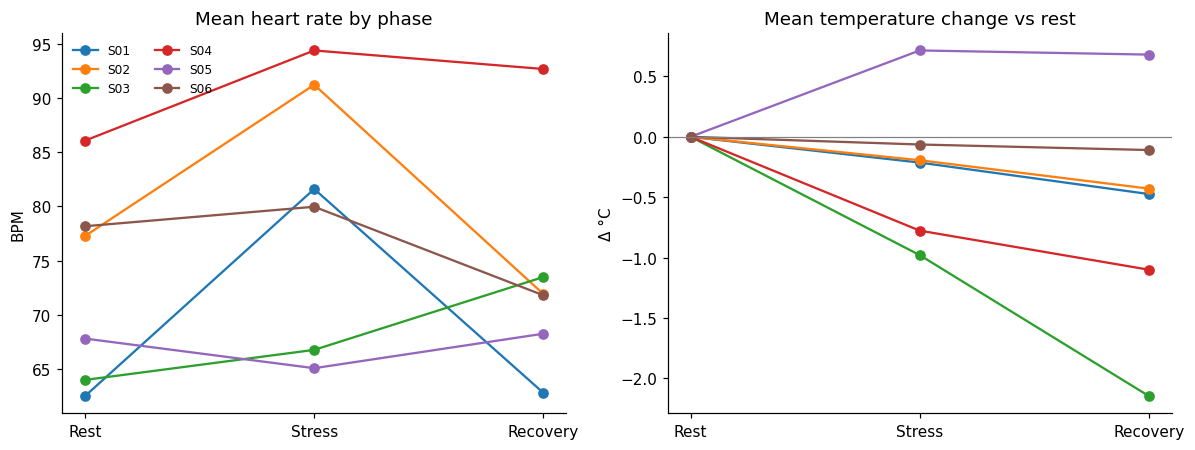

Heart rate higher in stress than rest (phase mean): 5 of 6 sessions
Peak 10-s rise of at least +5 BPM in the first minute of stress: 5 of 6 sessions
Median stress-minus-rest difference: +5.6 BPM; median peak rise: +12.3 BPM
Wilcoxon signed-rank on stress-minus-rest (n = 6): p = 0.094  (exploratory; the smallest possible p at n = 6 is 0.031)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
x = [0, 1, 2]
for sid, r in summary.iterrows():
    axes[0].plot(x, [r.bpm_rest, r.bpm_stress, r.bpm_recovery], marker="o", label=sid)
    axes[1].plot(x, [0, r.d_temp_stress, r.d_temp_recovery], marker="o", label=sid)
for ax, title, yl in zip(axes, ["Mean heart rate by phase", "Mean temperature change vs rest"], ["BPM", "Δ °C"]):
    ax.set_xticks(x); ax.set_xticklabels(["Rest", "Stress", "Recovery"])
    ax.set_title(title); ax.set_ylabel(yl)
axes[1].axhline(0, color="gray", lw=0.8)
axes[0].legend(ncol=2, fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_phase_means.png", dpi=150, bbox_inches="tight")
plt.show()

rose = int((summary.d_bpm_stress > 0).sum())
big = int((summary.peak_d_bpm >= 5).sum())
print(f"Heart rate higher in stress than rest (phase mean): {rose} of {len(summary)} sessions")
print(f"Peak 10-s rise of at least +5 BPM in the first minute of stress: {big} of {len(summary)} sessions")
print(f"Median stress-minus-rest difference: {summary.d_bpm_stress.median():+.1f} BPM; median peak rise: {summary.peak_d_bpm.median():+.1f} BPM")
w = stats.wilcoxon(summary.d_bpm_stress)
print(f"Wilcoxon signed-rank on stress-minus-rest (n = {len(summary)}): p = {w.pvalue:.3f}  (exploratory; the smallest possible p at n = 6 is 0.031)")

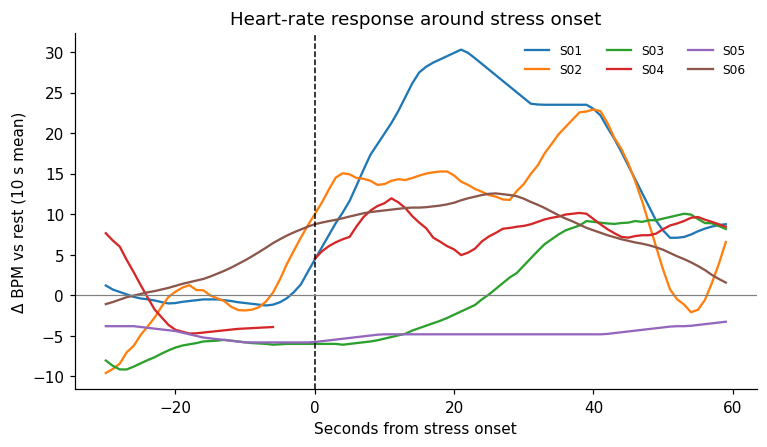

In [7]:
# Heart-rate time course around stress onset, relative to each session's rest mean
fig, ax = plt.subplots(figsize=(8, 4.2))
for sid, s in series.items():
    g = samples[samples.subject == sid]
    t0 = int(g.loc[g.fase == "estres", "elapsed_s"].min())
    rest = summary.loc[sid, "bpm_rest"]
    sm = s.bpm_i.rolling(10, center=True, min_periods=5).mean() - rest
    rel = sm.loc[t0 - 30: t0 + 59]
    ax.plot(rel.index - t0, rel.values, label=sid)
ax.axvline(0, color="black", lw=1, ls="--"); ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("Seconds from stress onset"); ax.set_ylabel("Δ BPM vs rest (10 s mean)")
ax.set_title("Heart-rate response around stress onset")
ax.legend(ncol=3, fontsize=8, frameon=False)
fig.savefig(FIG_DIR / "03_hr_onset.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Does temperature follow the phases, or just drift?

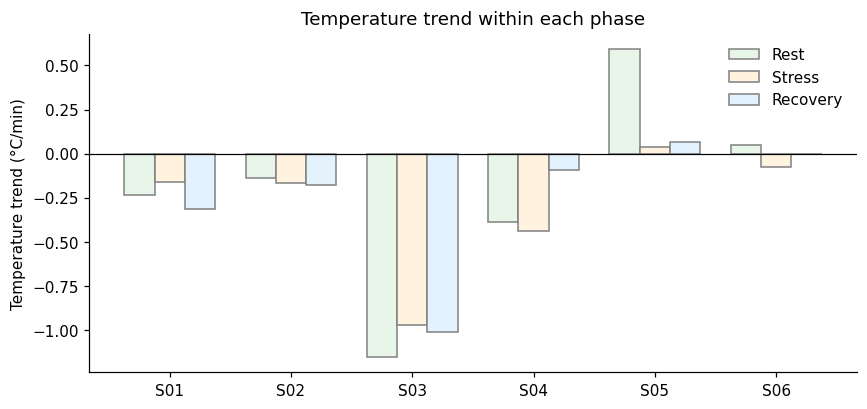

Temperature trend has the same sign in rest, stress and recovery in 5 of 6 sessions
Sensor resolution (DS18B20, 12-bit): 0.0625 °C. Largest total temperature change across a session: 2.15 °C


In [8]:
slopes = summary[["slope_rest", "slope_stress", "slope_recovery"]]
fig, ax = plt.subplots(figsize=(9, 4))
w_ = 0.25
for i, ph in enumerate(["slope_rest", "slope_stress", "slope_recovery"]):
    ax.bar(np.arange(len(slopes)) + (i - 1) * w_, slopes[ph], width=w_, label=LABEL[PHASES[i]], color=[SHADE[p] for p in PHASES][i], edgecolor="gray")
ax.set_xticks(range(len(slopes))); ax.set_xticklabels(slopes.index)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Temperature trend (°C/min)")
ax.set_title("Temperature trend within each phase")
ax.legend(frameon=False)
fig.savefig(FIG_DIR / "04_temp_slopes.png", dpi=150, bbox_inches="tight")
plt.show()

same_sign = int((np.sign(slopes).nunique(axis=1) == 1).sum())
print(f"Temperature trend has the same sign in rest, stress and recovery in {same_sign} of {len(slopes)} sessions")
print(f"Sensor resolution (DS18B20, 12-bit): 0.0625 °C. Largest total temperature change across a session: {summary[['d_temp_stress','d_temp_recovery']].abs().max().max():.2f} °C")

If temperature were driven by the stress task, its trend should change at the phase boundaries. A trend that keeps the same sign across all three phases looks more like the sensor and finger reaching thermal equilibrium (the documentation notes this takes one to three minutes) or the room temperature changing. A no-task control session would settle this.

## 6. Time lag between heart rate and temperature

For each session the linear trend is removed from both signals (to take out slow drift), then the correlation is computed with temperature shifted by a lag. A positive lag means temperature follows heart rate. With strongly autocorrelated signals and one session per person, treat this as descriptive only.

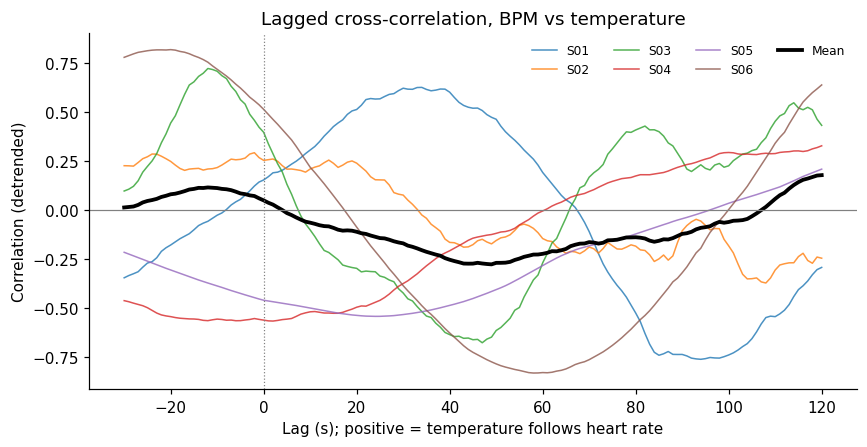

,r_lag0,best_lag_s,r_best
subject,,,
S01,0.15,85,-0.74
S02,0.25,84,-0.26
S03,0.40,47,-0.68
S04,-0.56,2,-0.57
S05,-0.46,24,-0.54
S06,0.51,58,-0.83


In [9]:
def detrend_z(x):
    t = np.arange(len(x)); ok = x.notna().values
    resid = x - np.polyval(np.polyfit(t[ok], x.values[ok], 1), t)
    return (resid - resid.mean()) / resid.std()

lags = list(range(-30, 121))
curves = {}
for sid, s in series.items():
    b, T = detrend_z(s.bpm_i), detrend_z(s.temp_i)
    curves[sid] = pd.Series({L: b.corr(T.shift(-L)) for L in lags})
curves = pd.DataFrame(curves)

best = []
for sid in curves:
    c = curves.loc[0:90, sid]
    L = c.abs().idxmax()
    best.append({"subject": sid, "r_lag0": curves.loc[0, sid], "best_lag_s": L, "r_best": c[L]})
best = pd.DataFrame(best).set_index("subject")

fig, ax = plt.subplots(figsize=(9, 4.2))
for sid in curves:
    ax.plot(curves.index, curves[sid], lw=1, alpha=0.8, label=sid)
ax.plot(curves.index, curves.mean(axis=1), color="black", lw=2.5, label="Mean")
ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8, ls=":")
ax.set_xlabel("Lag (s); positive = temperature follows heart rate")
ax.set_ylabel("Correlation (detrended)")
ax.set_title("Lagged cross-correlation, BPM vs temperature")
ax.legend(ncol=4, fontsize=8, frameon=False)
fig.savefig(FIG_DIR / "05_lagged_corr.png", dpi=150, bbox_inches="tight")
plt.show()
best.round(2)

In [10]:
print("Whole-session Pearson r (BPM vs temperature, the value the app shows):")
print(summary.pearson_all.round(2).to_string())
neg = int((summary.pearson_all < 0).sum())
print(f"\nNegative (as hypothesized) in {neg} of {len(summary)} sessions")
print(f"Lag with the largest |r| (0-90 s): median {best.best_lag_s.median():.0f} s, range {best.best_lag_s.min()}–{best.best_lag_s.max()} s")

Whole-session Pearson r (BPM vs temperature, the value the app shows):
subject
S01    0.09
S02    0.27
S03   -0.50
S04   -0.61
S05   -0.31
S06    0.70

Negative (as hypothesized) in 3 of 6 sessions
Lag with the largest |r| (0-90 s): median 52 s, range 2–85 s


## 7. Task performance

In [11]:
acc = summary[["task", "accuracy", "n_answers"]].copy()
acc["accuracy"] = (acc.accuracy * 100).round(0)
acc["note"] = np.where(acc.n_answers < 10, "too few answers recorded", "")
acc

,task,accuracy,n_answers,note
subject,,,,
S01,Stroop,60.0,5,too few answers recorded
S02,Stroop,89.0,46,
S03,Stroop,100.0,43,
S04,Stroop,80.0,30,
S05,PASAT,40.0,159,
S06,Stroop,72.0,120,


## 8. Conclusions

- **Heart rate responded to the task in most sessions.** At stress onset the 10-s heart rate rose by +10 to +30 BPM in 5 of 6 sessions (median across all six sessions +12.3 BPM). The exception is S05 (PASAT), where it did not rise. Phase means understate this because heart rate often peaks early and then falls back while the task continues (visible in S06). With n = 6, the stress-minus-rest difference is not distinguishable from zero (Wilcoxon p = 0.094).
- **Recovery was inconsistent.** Heart rate returned to its rest level or below in 4 of 6 sessions (S01, S02, S05, S06) but stayed 7–10 BPM above rest in S03 and S04.
- **Temperature did not follow the phases.** In 5 of 6 sessions its trend kept the same sign through rest, stress and recovery (cooling in four, warming in S05), and changes reached up to 2.15 °C (S03). This looks like drift (sensor/finger equilibrium or room temperature) rather than a stress response, and it cannot be separated from one without a control session.
- **The whole-session Pearson coefficient is not a reliable summary.** It was negative, as hypothesized, in only 3 of 6 sessions (S03, S04, S05), and positive in the others.
- **Lagged analysis is suggestive but weak.** After removing linear trends, the strongest correlation within a 0–90 s lag was negative in all six sessions (−0.26 to −0.83), meaning higher heart rate tended to be followed by lower temperature. The lag varied widely (2–85 s, median 52 s). Because the best of 91 lags was picked from autocorrelated signals, these values are optimistic and are not evidence of a physiological link.
- **Bottom line:** the data support a heart-rate response to the cognitive task in most participants, and do not support an instantaneous heart-rate–temperature relationship. Temperature findings are inconclusive until a no-task control and longer, insulated recordings are available.

## 9. Limitations and next steps

- Six sessions, one participant each, mixed tasks (five Stroop, one PASAT) and mixed app versions; no control session.
- Rest, stress and recovery lasted 60 s in several sessions, which is short for peripheral temperature to respond.
- Temperature resolution is coarse relative to the changes observed (0.0625 °C steps).
- Some stretches show heart rate frozen at one exact value for 20 s or more (for example S03 near the end of recovery), which suggests a held value rather than live beats. These segments were not removed.
- Next: record 4 to 6 more sessions with the default durations (120 / 180 / 120 s), plus 1 to 2 no-task control sessions; insulate the temperature sensor from room air; load all sessions into a SQLite database.